In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [43]:
df = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

In [15]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [16]:
categorical_cols = ["MSSubClass", "MSZoning", "Street", "Alley", "LotShape", "LandContour", "Utilities", "LotConfig", "LandSlope", "Neighborhood", "Condition1", "Condition2", "BldgType", "HouseStyle", "OverallQual", "OverallCond", "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd", "MasVnrType", "ExterQual", "ExterCond", "Foundation", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "Heating", "HeatingQC", "CentralAir", "Electrical", "KitchenQual", "Functional", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PavedDrive", "PoolQC", "Fence", "MiscFeature", "SaleType", "SaleCondition"]
numerical_cols = list(set(df.columns) - set(categorical_cols))

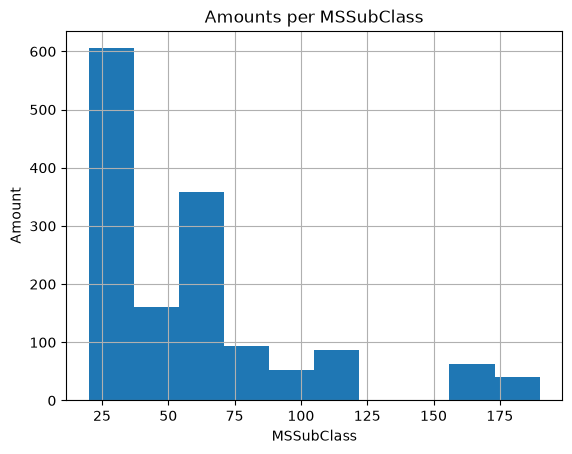

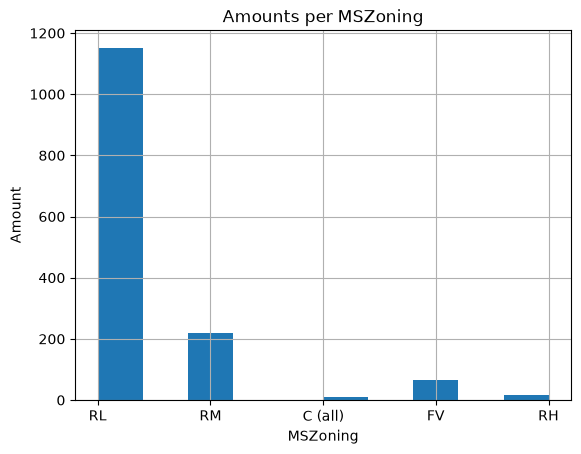

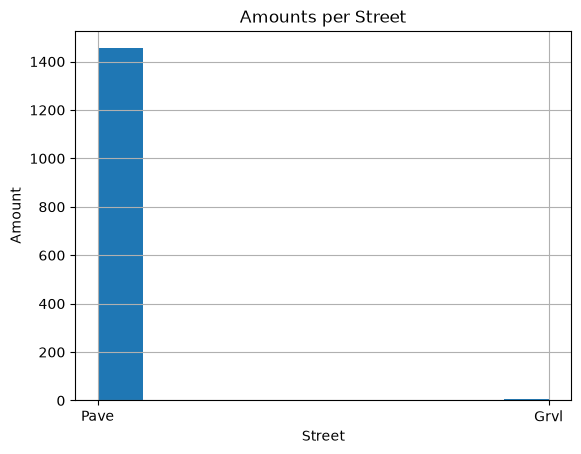

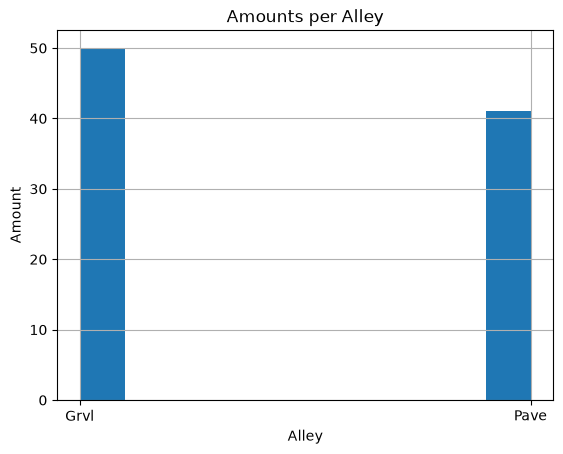

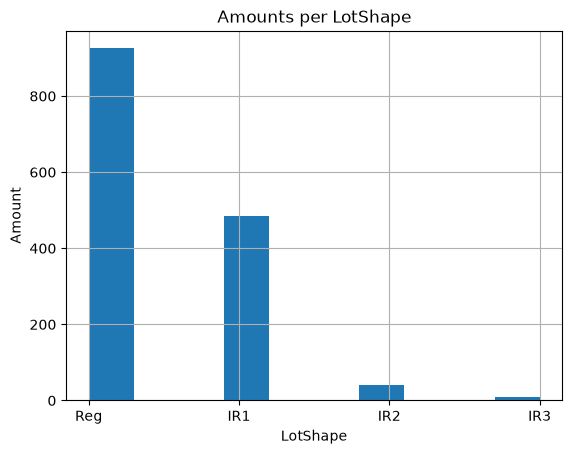

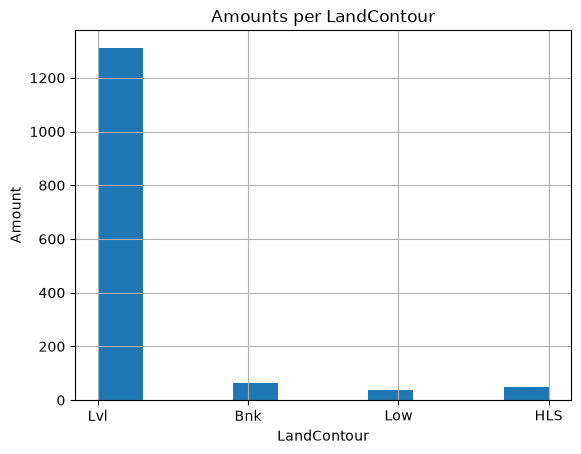

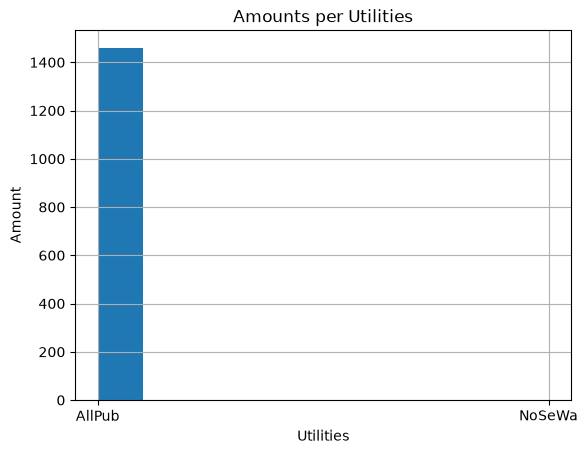

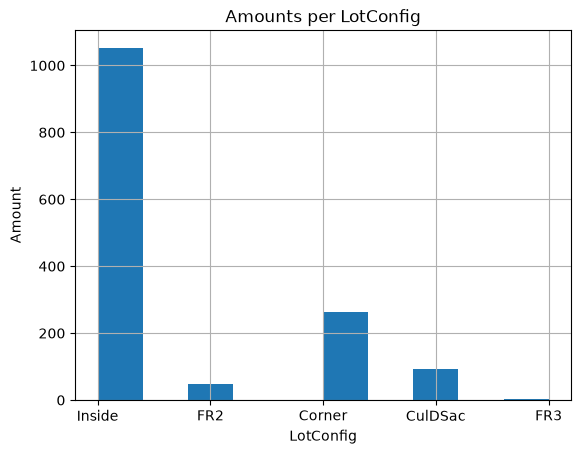

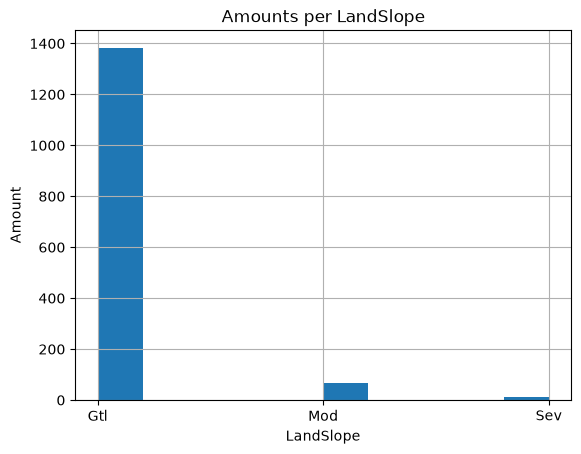

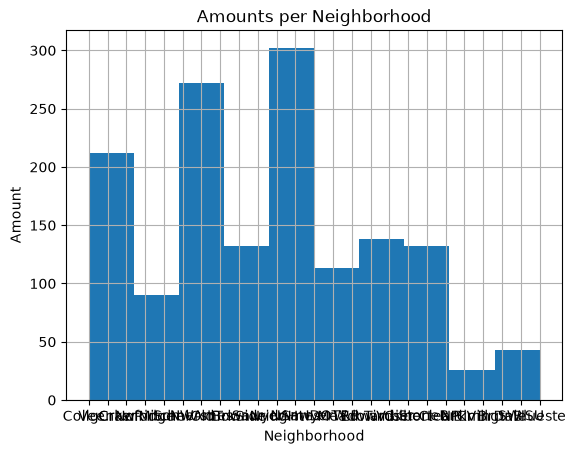

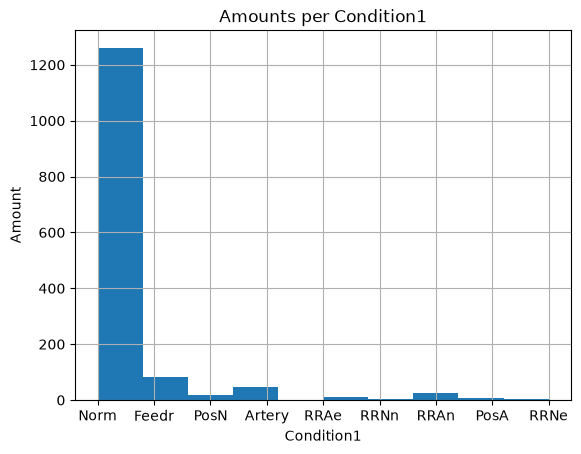

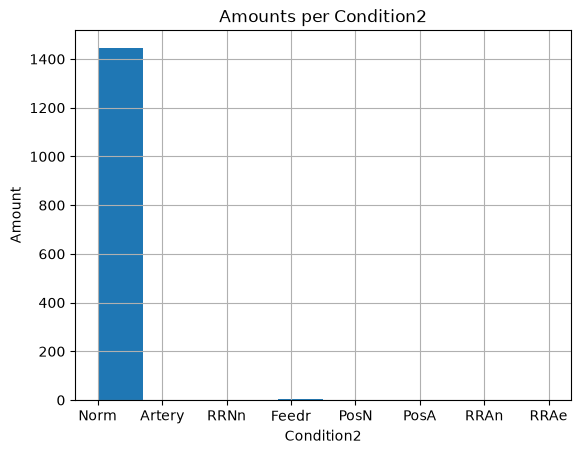

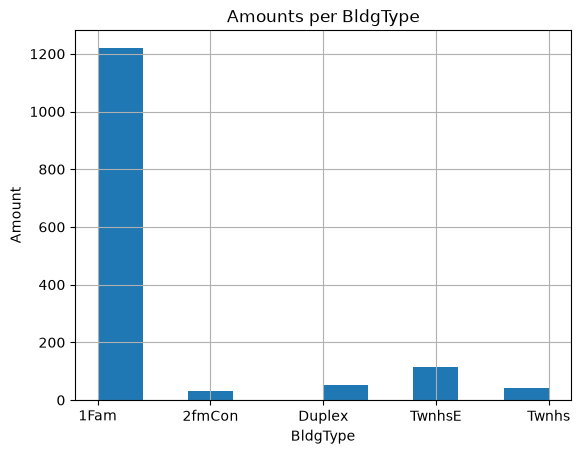

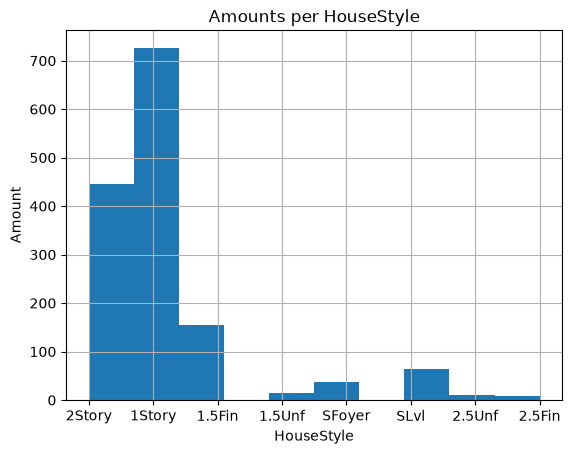

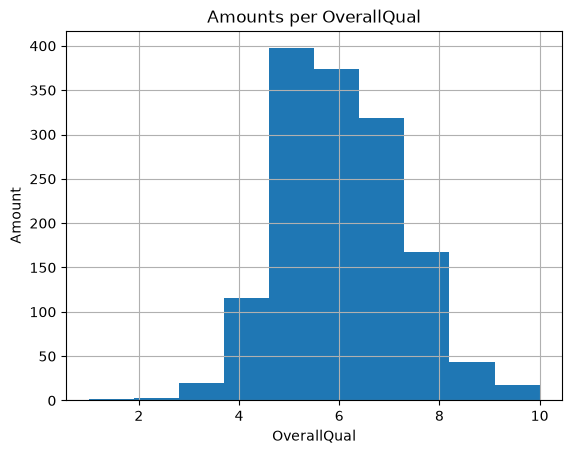

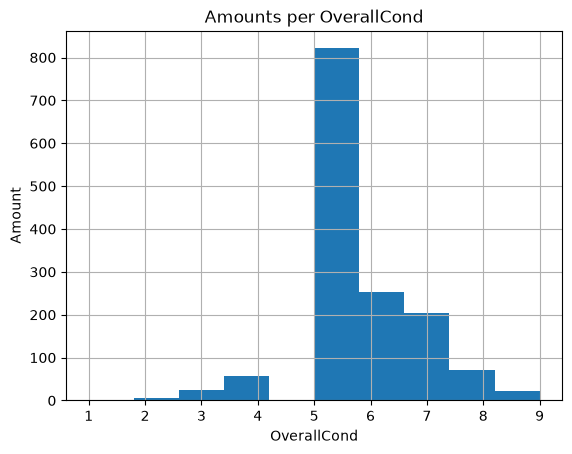

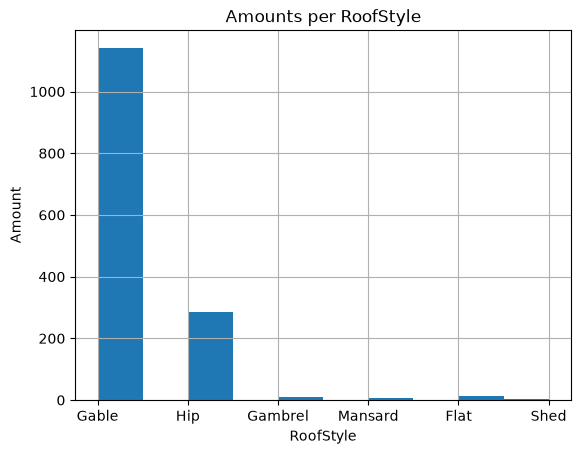

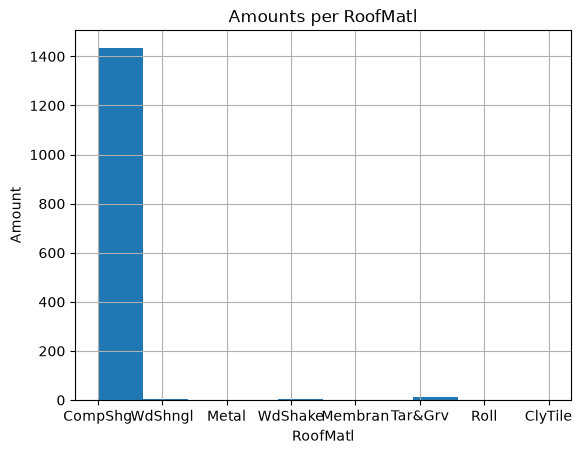

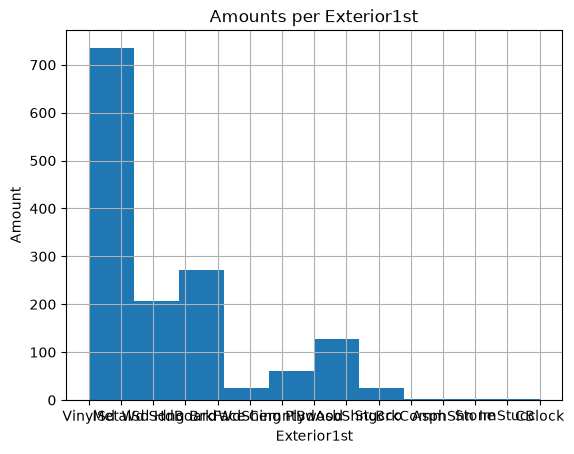

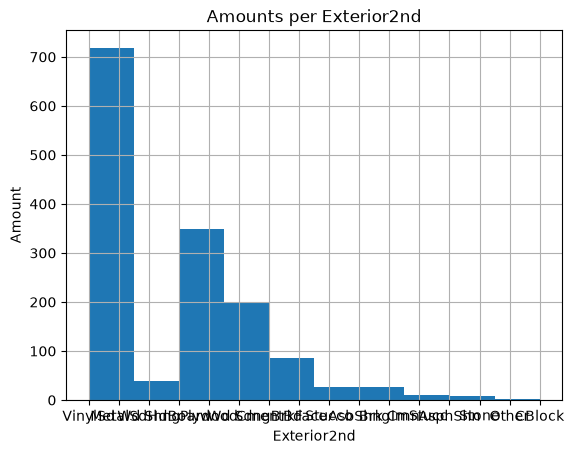

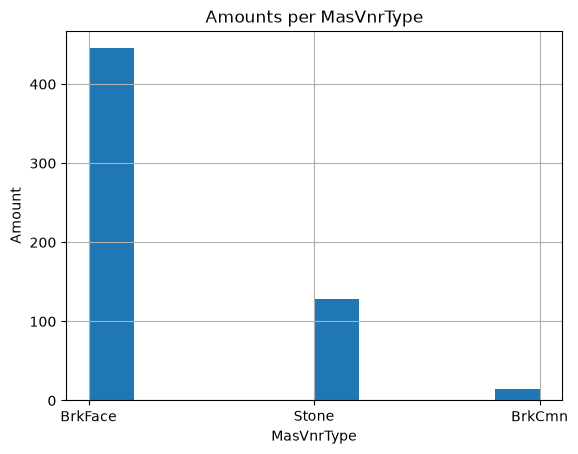

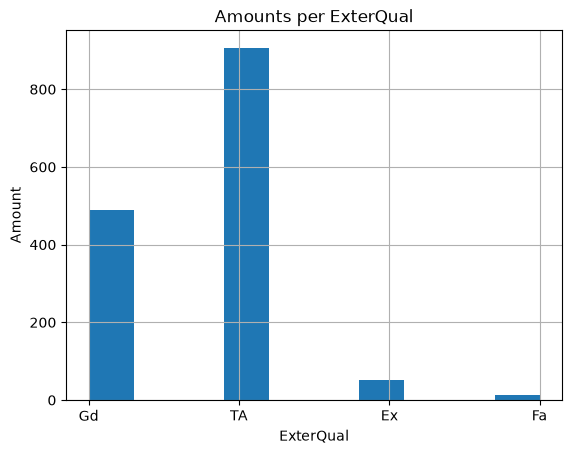

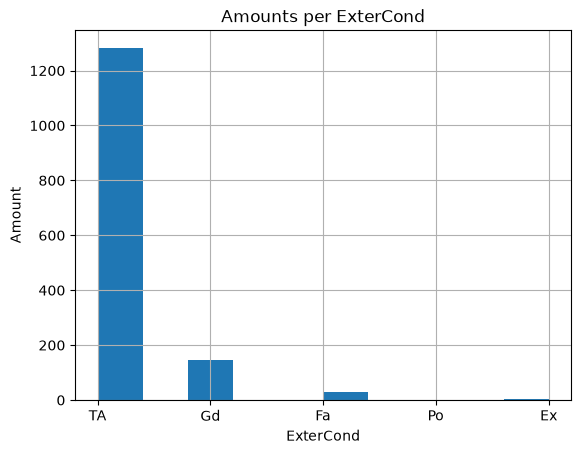

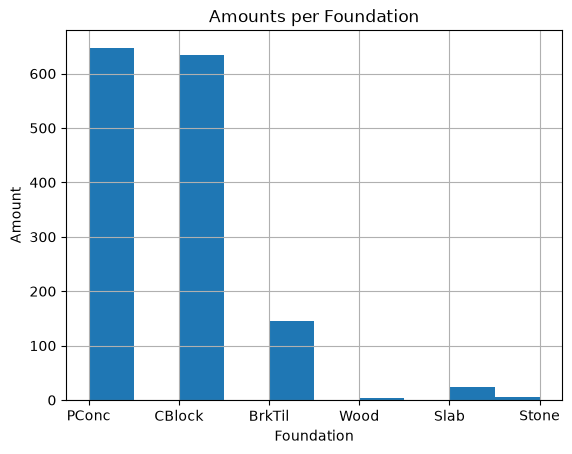

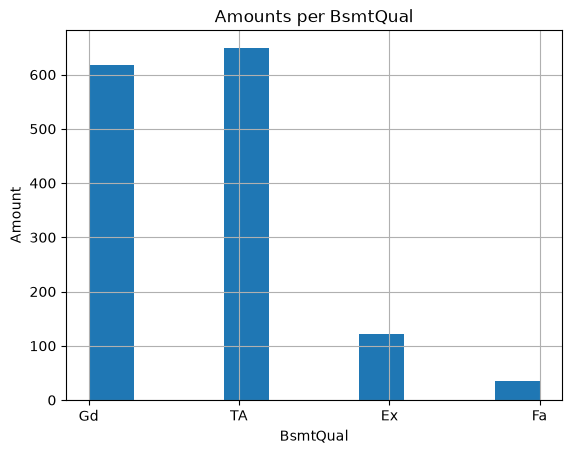

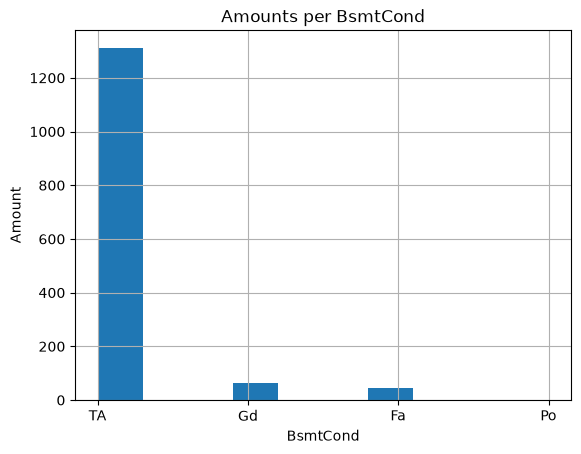

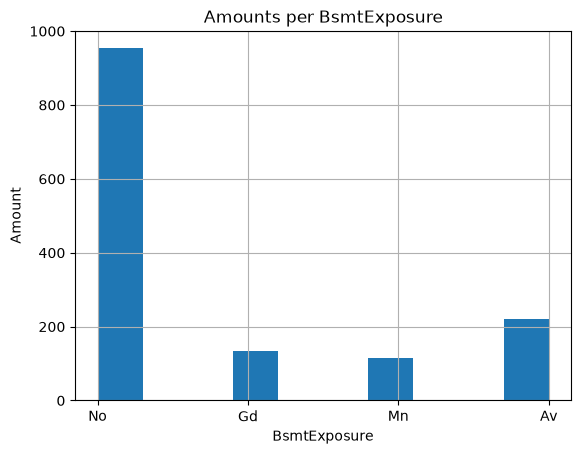

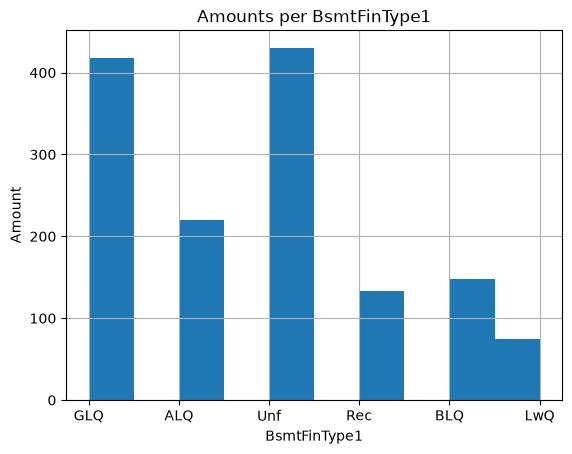

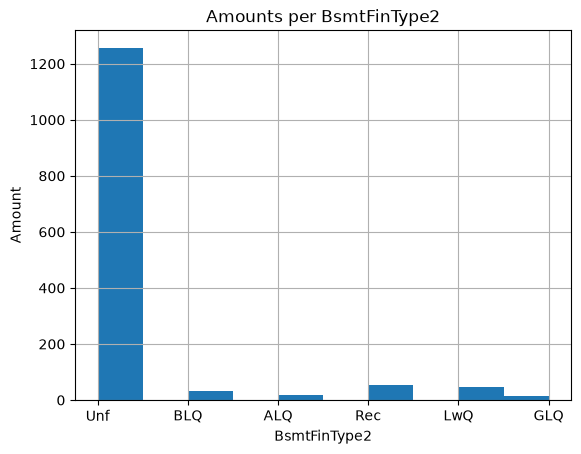

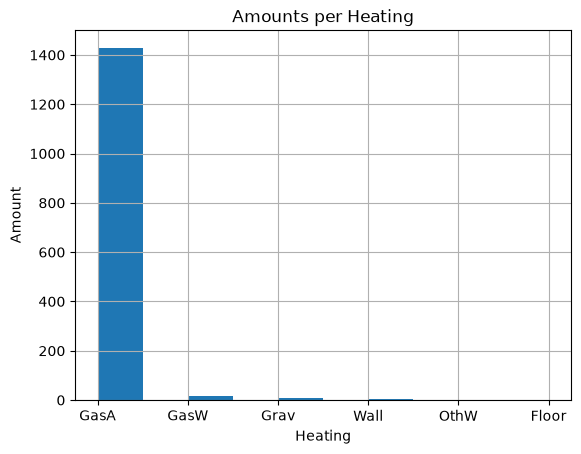

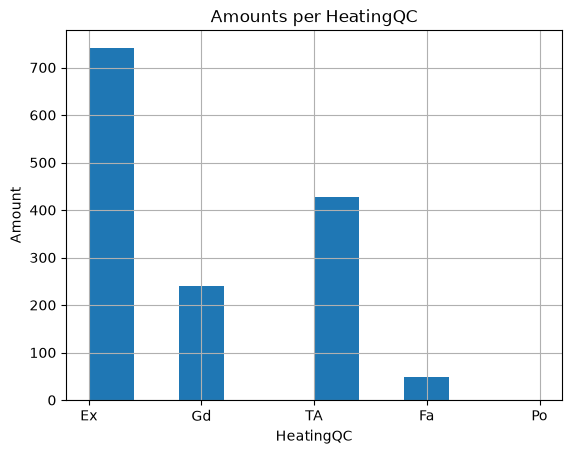

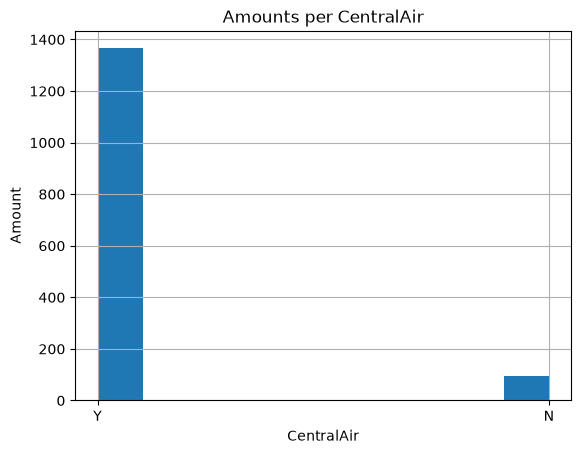

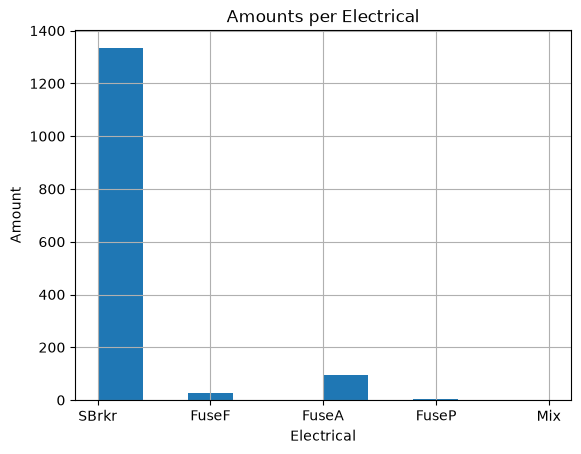

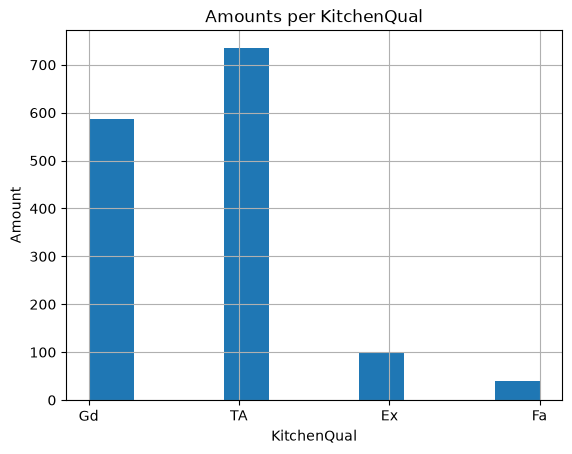

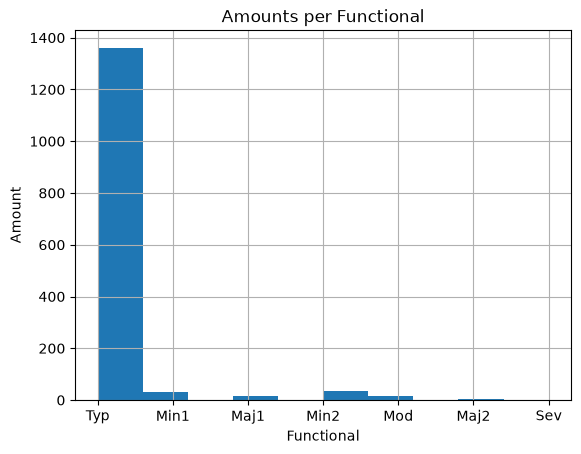

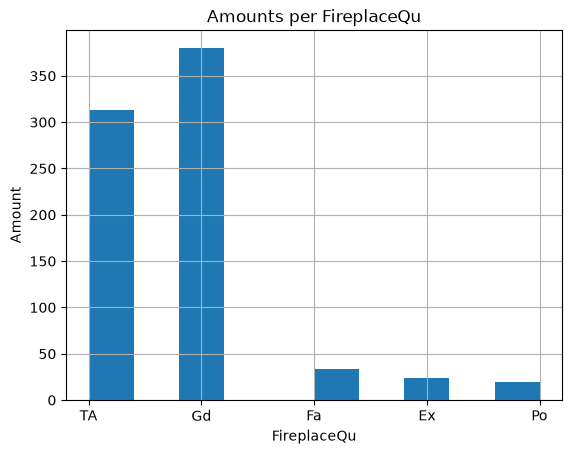

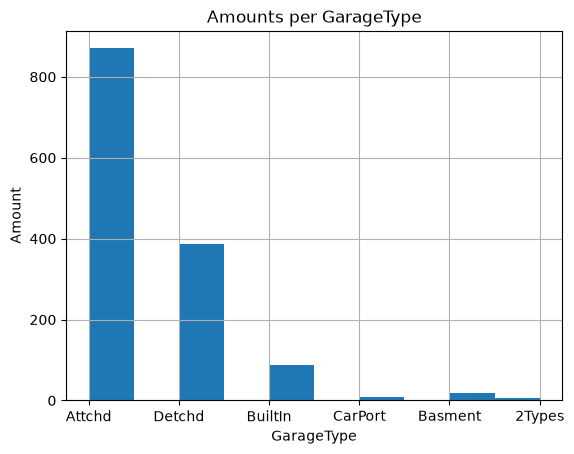

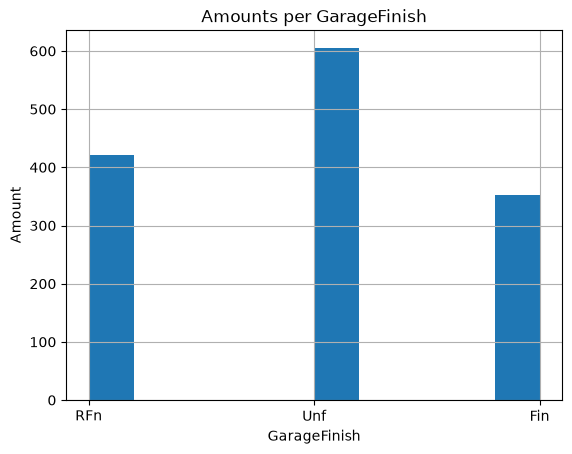

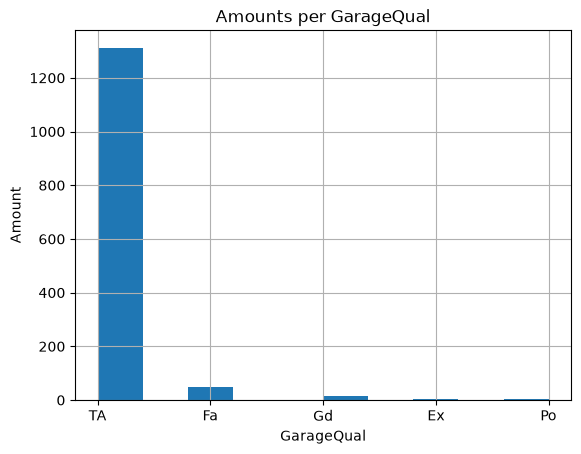

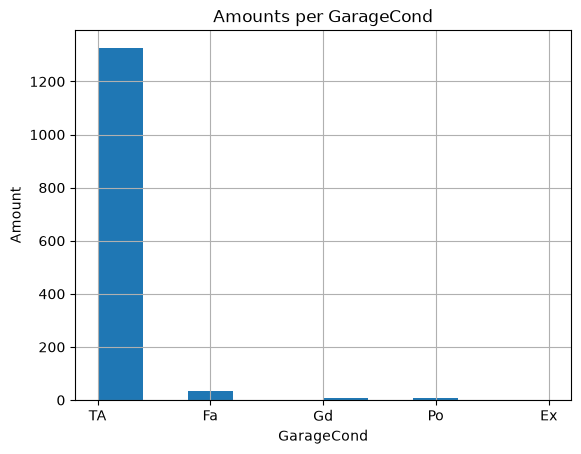

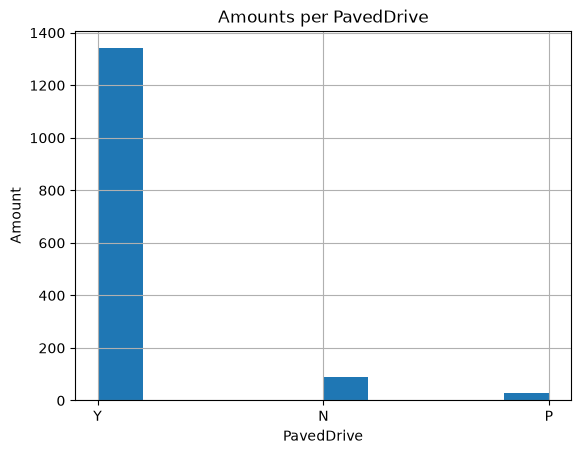

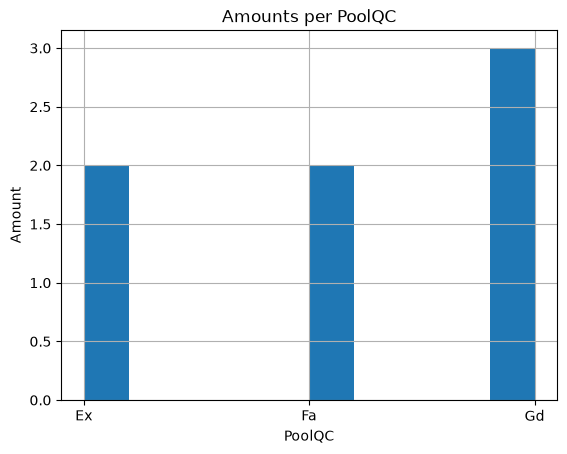

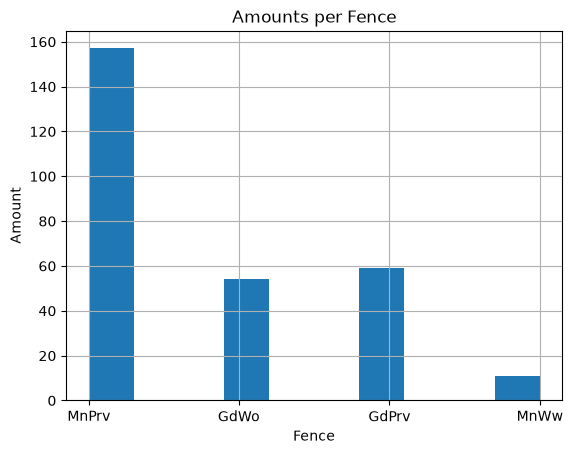

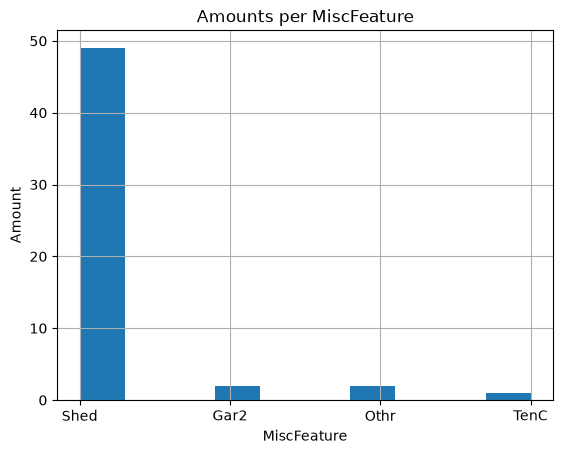

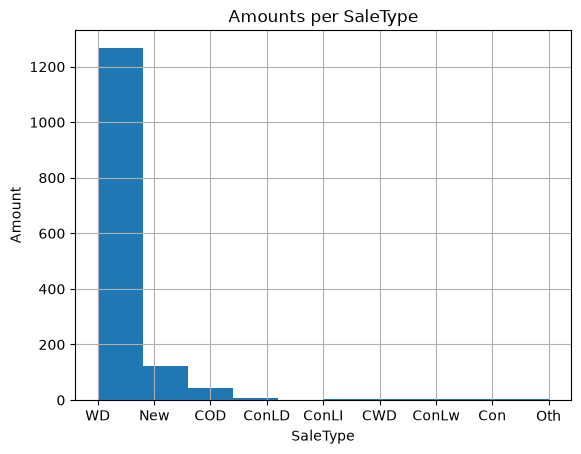

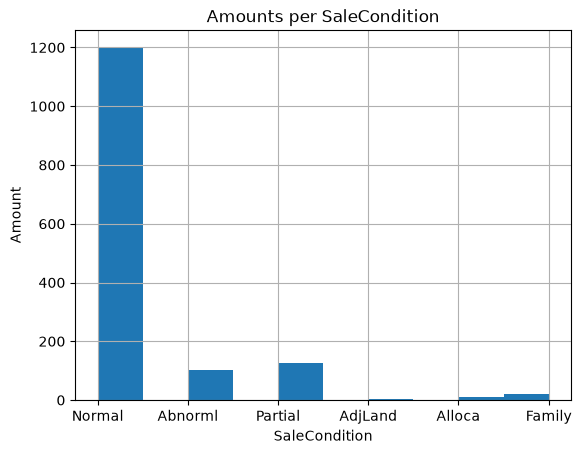

In [17]:
for col in categorical_cols:
    df[col].hist()
    plt.title(f"Amounts per {col}")
    plt.xlabel(col)
    plt.ylabel("Amount")
    plt.show()

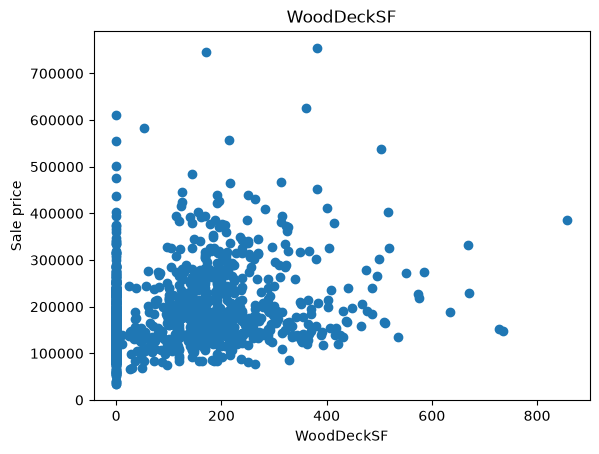

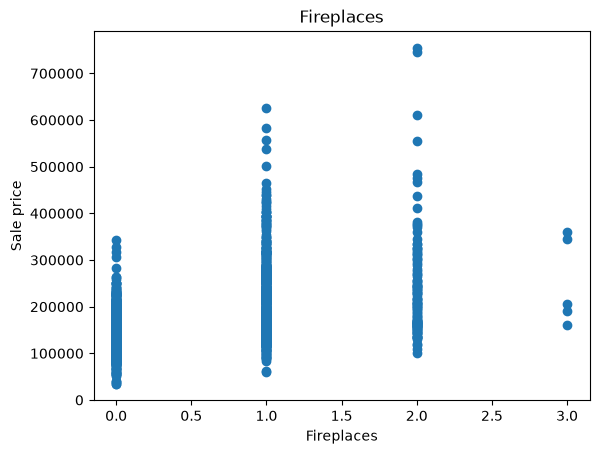

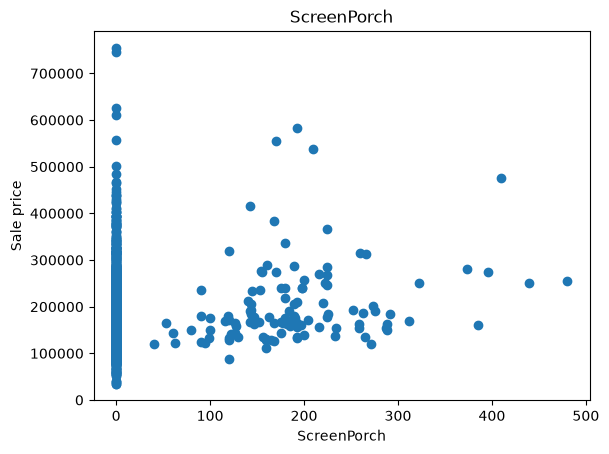

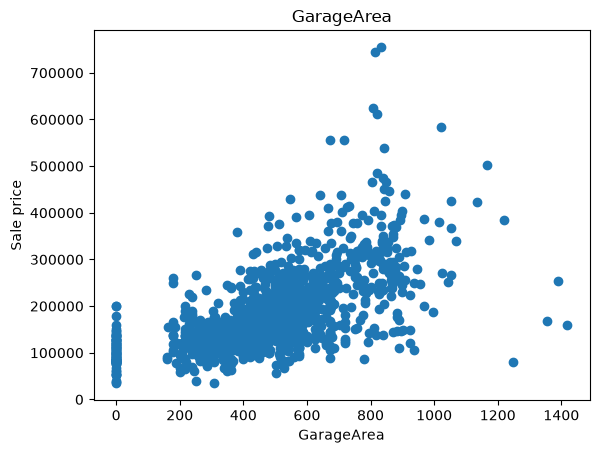

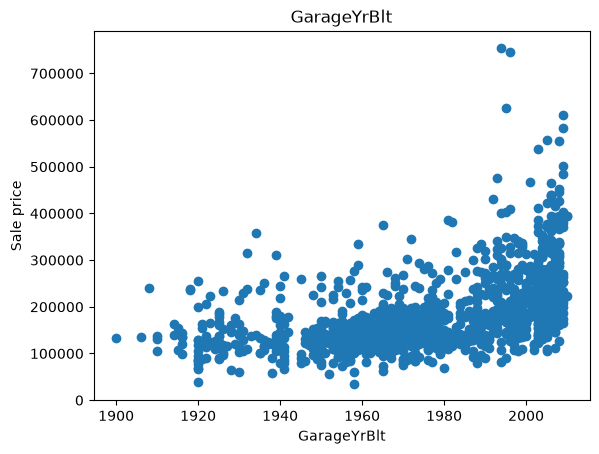

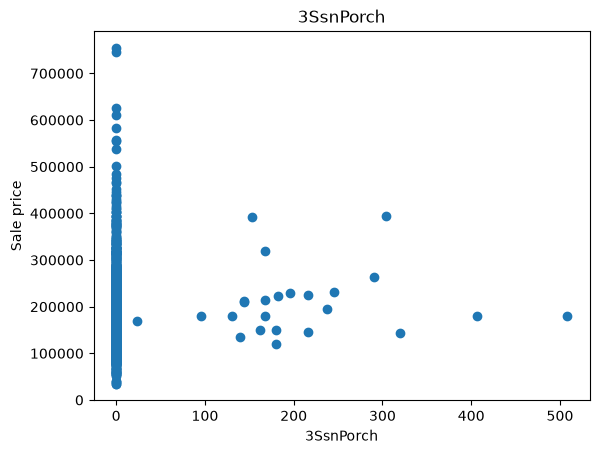

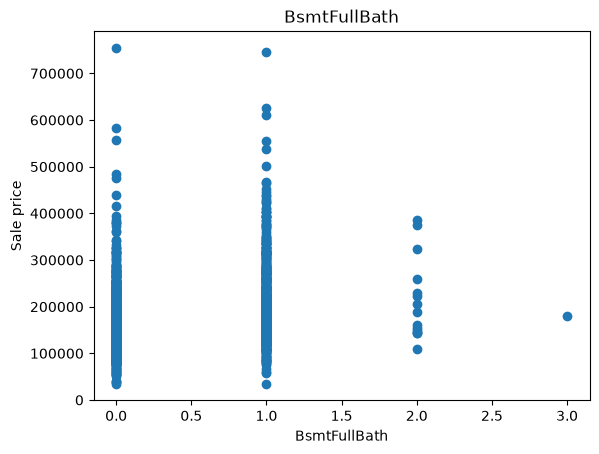

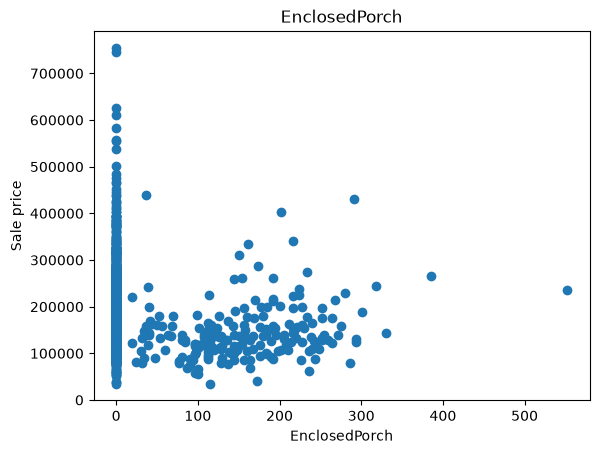

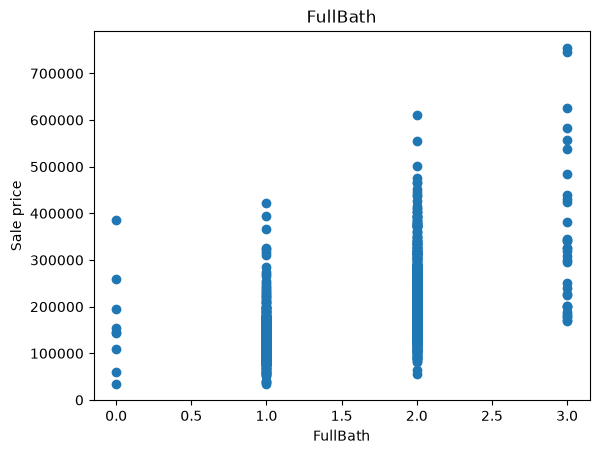

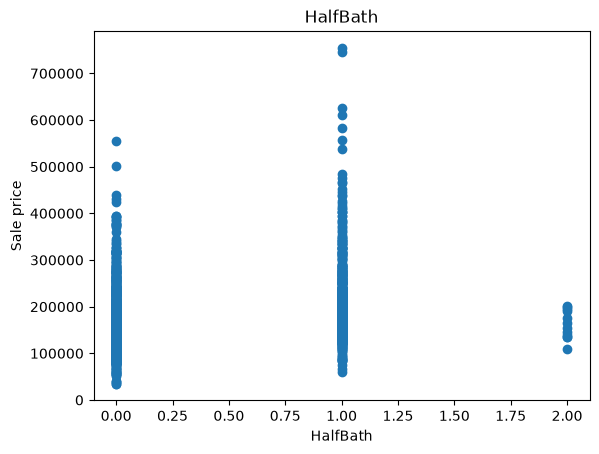

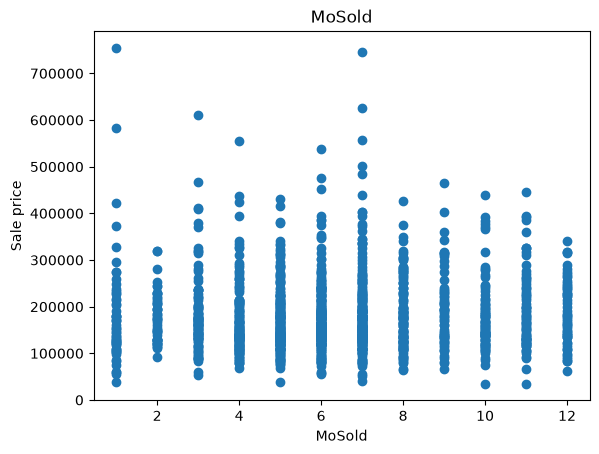

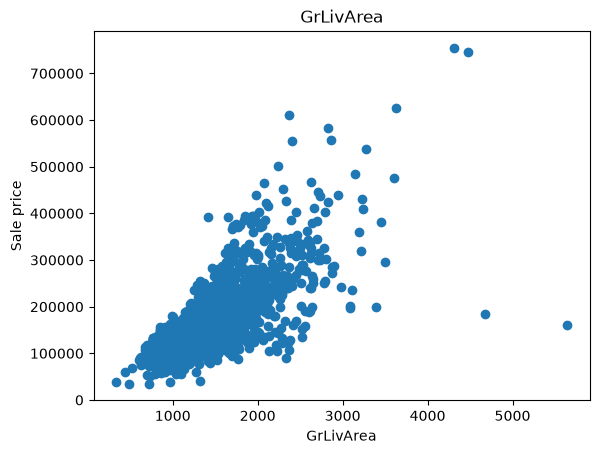

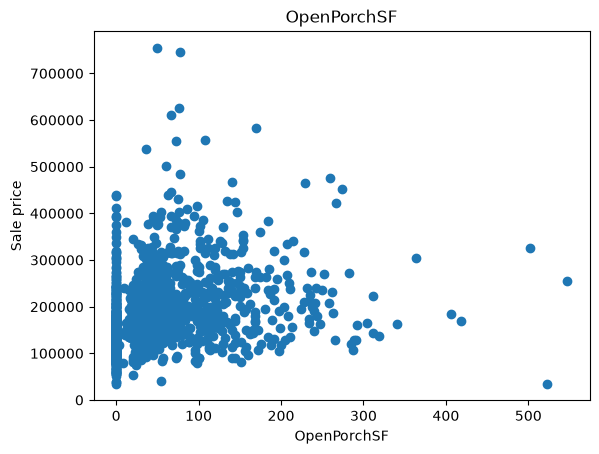

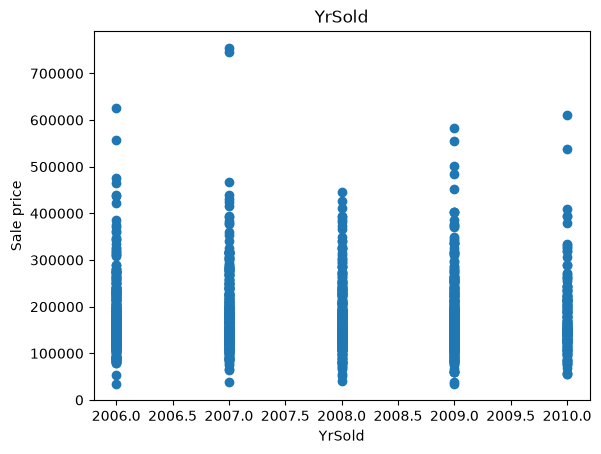

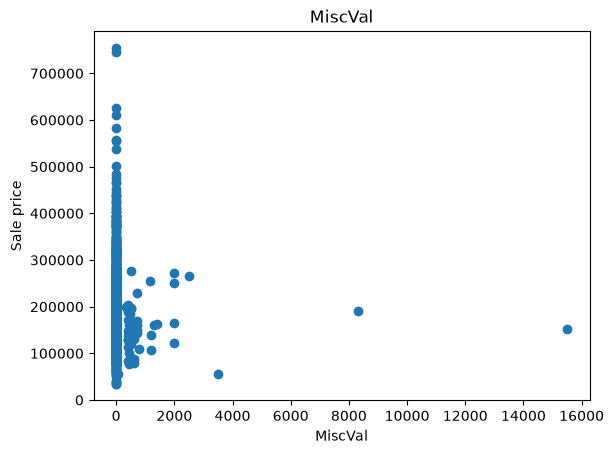

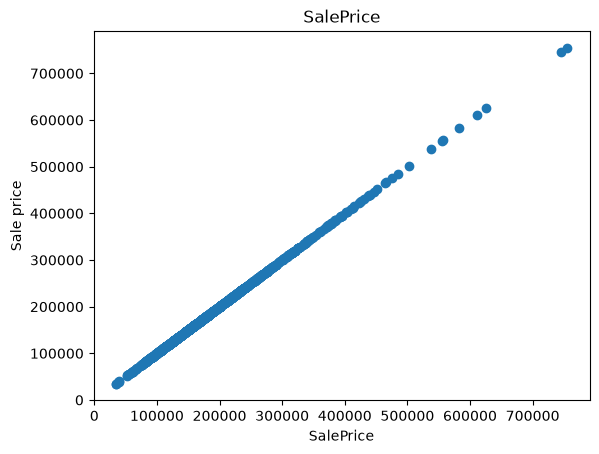

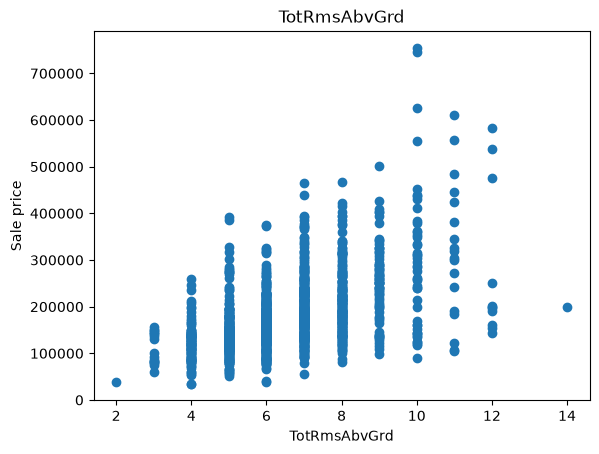

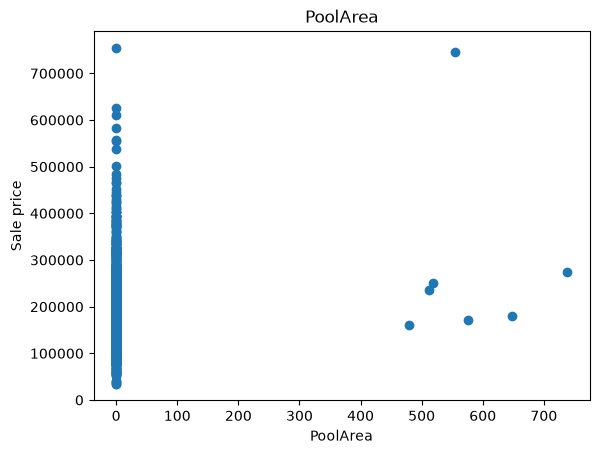

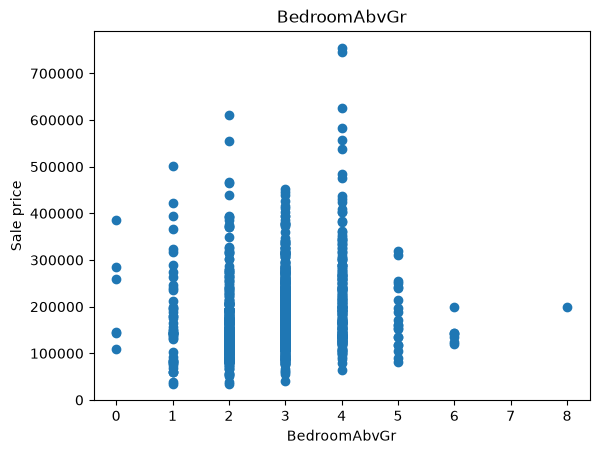

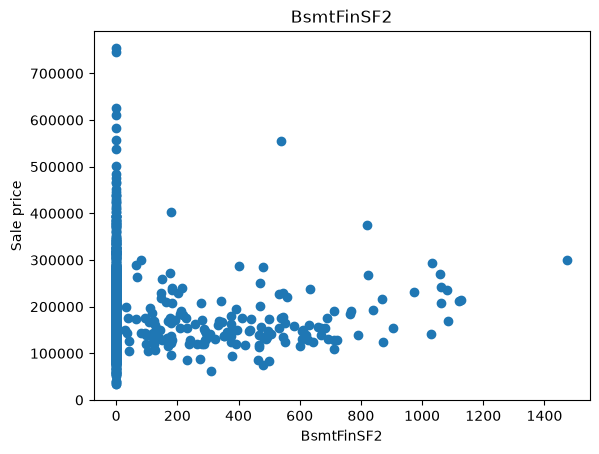

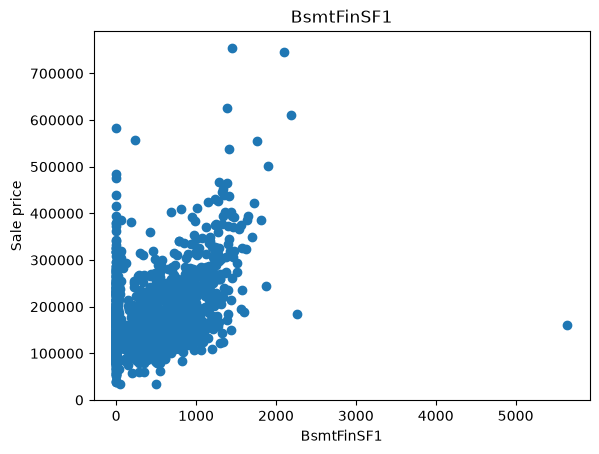

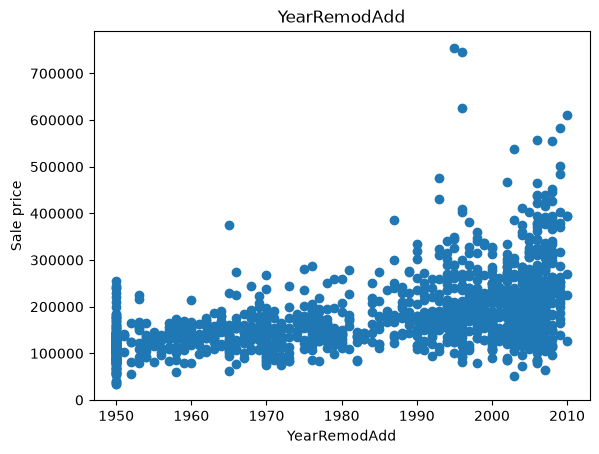

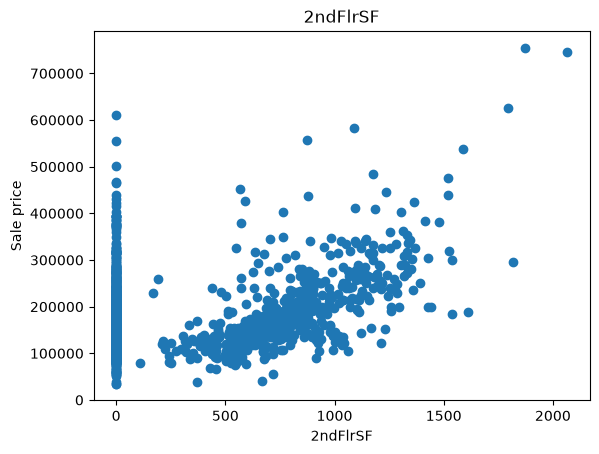

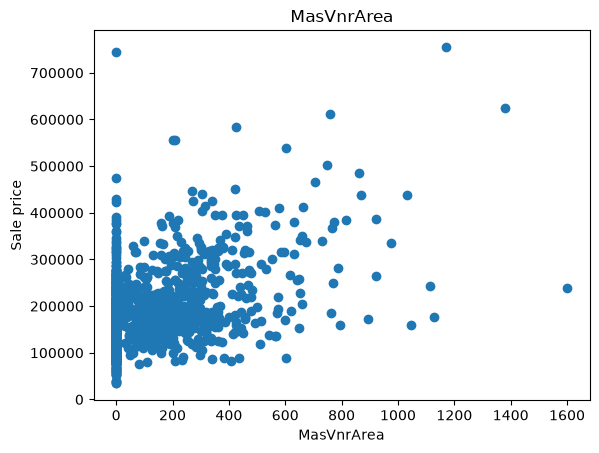

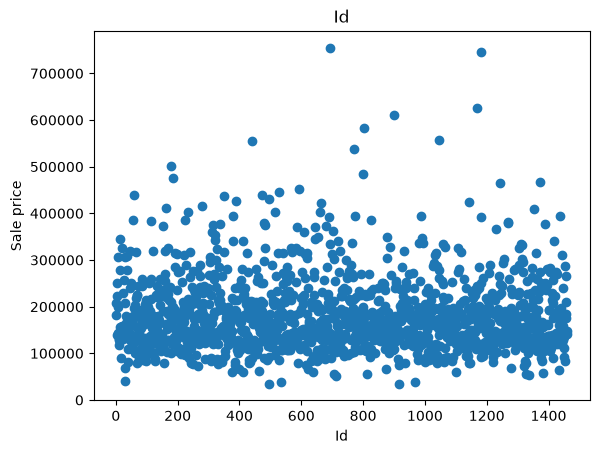

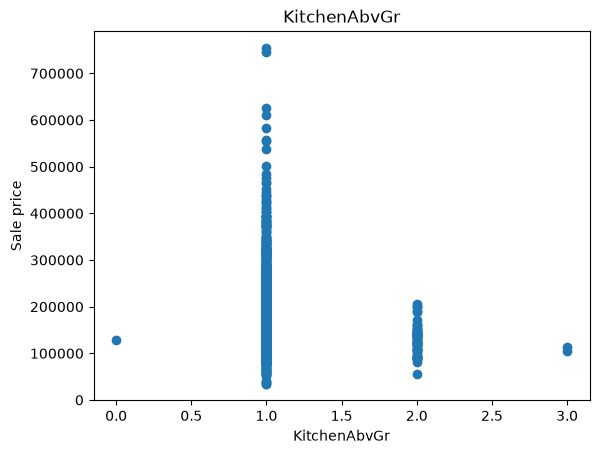

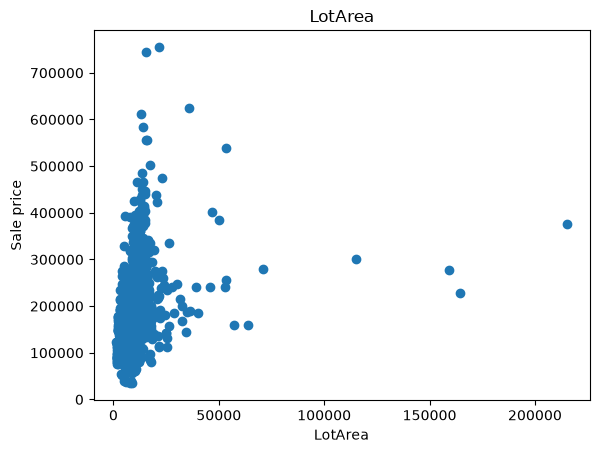

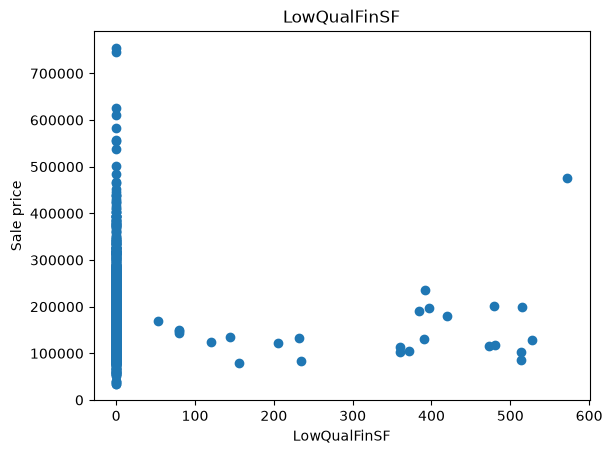

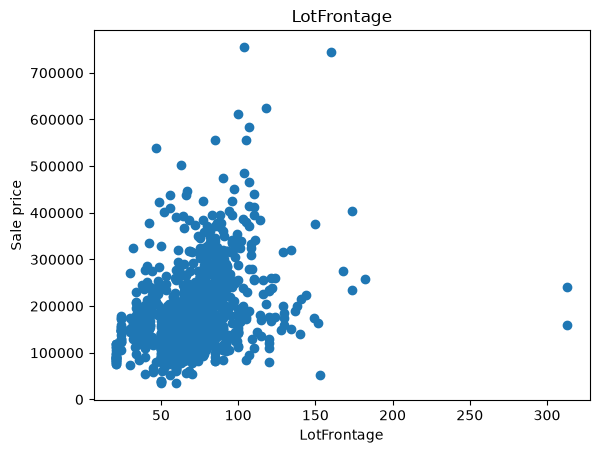

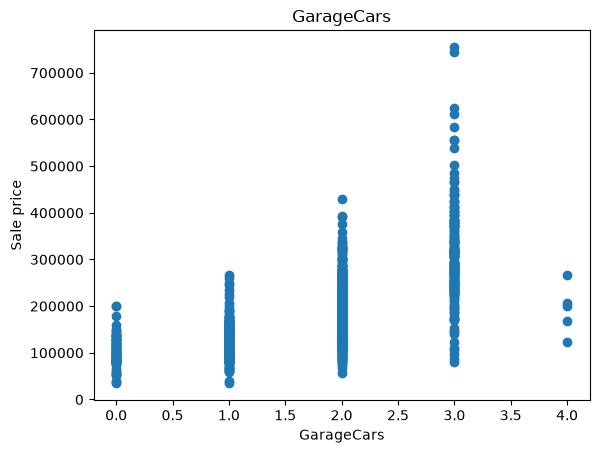

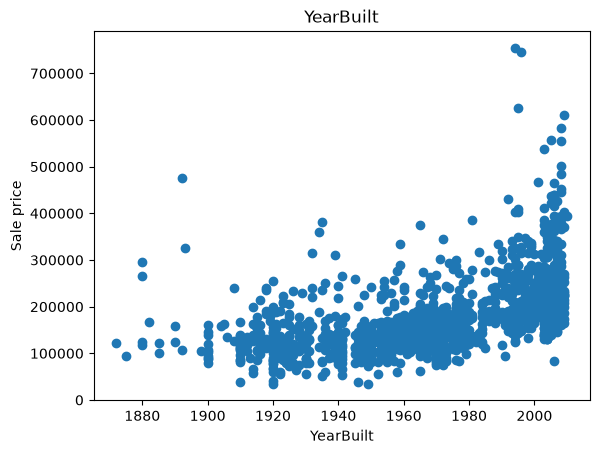

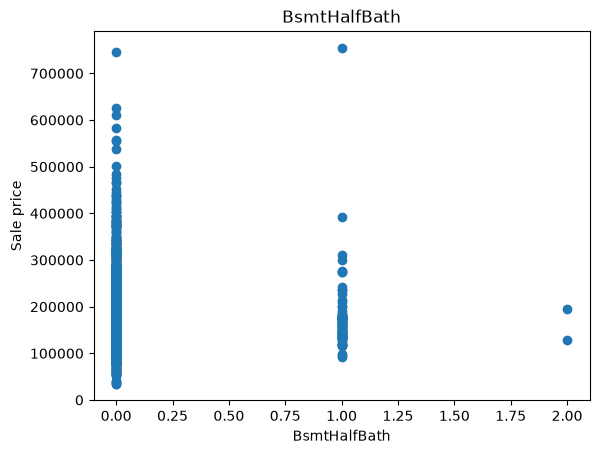

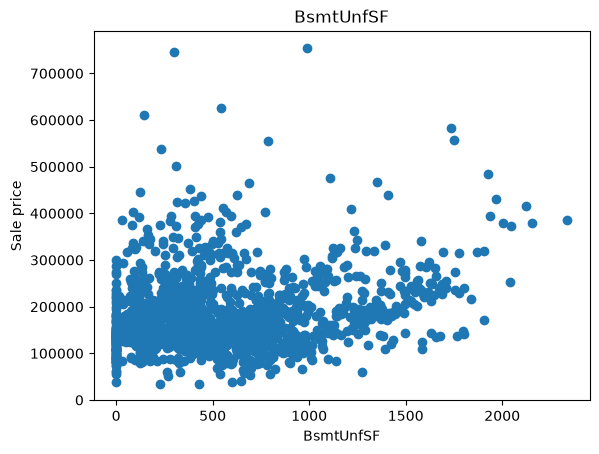

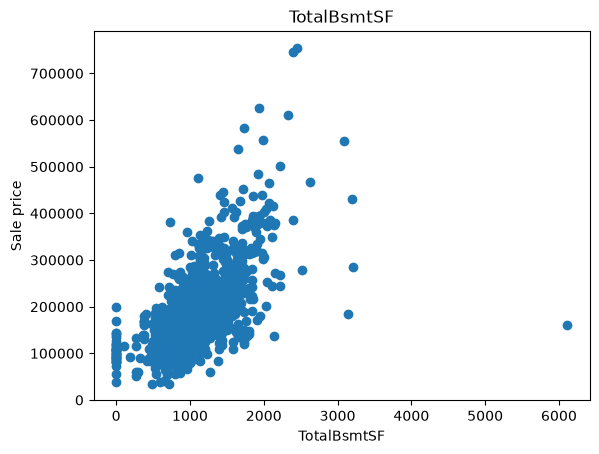

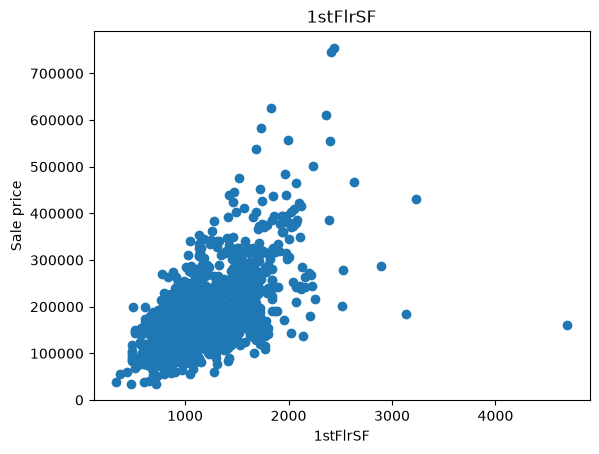

In [23]:
for col in numerical_cols:
    plt.scatter(df[col], df["SalePrice"])
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Sale price")
    plt.show()

Dropping unnecessary columns

In [ ]:
print(len(df[df["Street"] == "Grvl"]))
print(pd.pivot_table(
    df,
    values = ["SalePrice"],
    index = ["Street"],
    aggfunc = "mean"
))
df = df.drop(["Street"], axis = 1)

In [ ]:
print(len(df[df["Utilities"] == "NoSeWa"]))
print(pd.pivot_table(
    df,
    values = ["SalePrice"],
    index = ["Utilities"],
    aggfunc = "mean"
))
df = df.drop(["Utilities"], axis = 1)

In [20]:

for val in df["Condition2"].unique():
    print (len(df[df["Condition2"] == val]))

print(pd.pivot_table(
    df,
    values = ["SalePrice"],
    index = ["Condition2"],
    aggfunc = "mean"
))
df = df.drop(["Condition2"], axis = 1)

1445
2
2
6
2
1
1
1
                SalePrice
Condition2               
Artery      106500.000000
Feedr       121166.666667
Norm        181169.405536
PosA        325000.000000
PosN        284875.000000
RRAe        190000.000000
RRAn        136905.000000
RRNn         96750.000000


In [21]:
for val in df["RoofMatl"].unique():
    print (len(df[df["RoofMatl"] == val]))

print(pd.pivot_table(
    df,
    values = ["SalePrice"],
    index = ["RoofMatl"],
    aggfunc = "mean"
))
df = df.drop(["RoofMatl"], axis = 1)

1434
6
1
5
1
11
1
1
              SalePrice
RoofMatl               
ClyTile   160000.000000
CompShg   179803.679219
Membran   241500.000000
Metal     180000.000000
Roll      137000.000000
Tar&Grv   185406.363636
WdShake   241400.000000
WdShngl   390250.000000


In [ ]:
# Are newer houses more expensive?
# Compressing this feature and YearRemodAdd, because it also has the YearBuilt feature in it (but also remodel date)
print(df[df["YearBuilt"] > 1980]["SalePrice"].mean(), len(df[df["YearBuilt"] > 1980]), "rows")
print(df[df["YearBuilt"] <= 1980]["SalePrice"].mean(), len(df[df["YearBuilt"] <= 1980]), "rows")

df = df.drop(["YearBuilt"], axis = 1)

234623.22757475084 602 rows
143242.14801864803 858 rows


In [ ]:
# YearRemodAdd: Are average prices higher when there even has been a remodel?

df['Remodel'] = [1 if df.loc[i]["YearBuilt"] != df.loc[i]["YearRemodAdd"] else 0 for i in range(len(df))]
print(pd.pivot_table(
    df,
    values = ["SalePrice"],
    index = ["Remodel"],
    aggfunc = "mean"
))
print("Creating a 'hasBeenRemodeled'-feature makes no sense.")


print(df[df["YearRemodAdd"] > 1980]["SalePrice"].mean(), len(df[df["YearRemodAdd"] > 1980]), "rows")
print(df[df["YearRemodAdd"] <= 1980]["SalePrice"].mean(), len(df[df["YearRemodAdd"] <= 1980]), "rows")

df['RemodelBuildYear'] = [1 if x > 1980 else 0 for x in df['YearBuilt']]
df = df.drop(["YearRemodAdd"], axis = 1)

             SalePrice
Remodel               
0        182583.659686
1        179096.307471
764
696
211874.4193548387 868 rows
135537.0777027027 592 rows


In [ ]:
# Questions: is finish overall the same? may compress those
# Extracting floors types etc
# PoolQC: extract 'pool' feature
# Sale type: some sale types may be for poorer people, etc